# Pipeline Gardenia | Etapa 8: Insights finais

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Anlbp/Projeto-Gardenia-unifeob/blob/main/recursos/dados/notebook_dados_nao_filtrados/08_insights.ipynb)

Reúne os resultados das etapas anteriores e transforma em **achados, recomendações, limitações e próximos passos**. Cada achado é calculado a partir dos arquivos gerados antes, com o número e o nível de confiança ao lado. Quando uma diferença pode ser só acaso, o notebook testa e diz.

**Lê (gerados pelas etapas anteriores):**

| Pasta | Arquivos | Gerado por |
|---|---|---|
| `saida/` | `trusted_*`, `quarentena_*`, `relatorio_qualidade_N.csv` | notebook 03 (ou `pipeline_vm2.py`) |
| `dw/` | `fato_vendas_N.csv`, `dim_cliente_N.csv`, `dim_produto_N.csv`, `dim_data_N.csv` | notebook 04 |
| `ml/` | `perfil_clusters_N.csv`, `avaliacao_k_N.csv`, `rfm_clientes_N.csv` | notebook 06 |
| `spark/` (opcional) | `perfil_segmentos.csv`, `resumo_lotes.csv` | notebook 07 ou `pipeline_vm3.py` |

**Gera:** `insights_N.md` (relatório) e `insights_N.png` (painel de gráficos), por padrão em `{DRIVE_PASTA}/insights`.

> **Leia antes de usar os resultados:** os dados vêm de um simulador, então as conclusões valem para **este conjunto de dados**, não para o comércio real. A seção de limitações no fim explica o que isso muda.

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Configuração e leitura

In [3]:
# ============================ CONFIGURAÇÃO ============================
FONTE = "drive"             # "drive" | "local"
LOTE = "1"                  # mesmo lote usado nos notebooks 03 a 06

DRIVE_PASTA = "/content/drive/MyDrive/gardenia"   # pasta onde as etapas anteriores gravaram
PASTA_LOCAL = "."           # usado quando FONTE == "local": deve conter saida/, dw/, ml/ (e spark/)

ALPHA = 0.05                # nível de significância dos testes estatísticos
SALVAR_NO_DRIVE = True      # True: grava em {DRIVE_PASTA}/insights. False: grava em ./insights
# =======================================================================

In [4]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

if FONTE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = DRIVE_PASTA
elif FONTE == "local":
    BASE = PASTA_LOCAL
else:
    raise ValueError('FONTE deve ser "drive" ou "local".')

GERADOR = {"saida": "notebook 03", "dw": "notebook 04", "ml": "notebook 06", "spark": "notebook 07"}


def ler(pasta, nome, obrigatorio=True):
    caminho = os.path.join(BASE, pasta, nome)
    if not os.path.exists(caminho):
        if obrigatorio:
            raise FileNotFoundError(
                f"Não encontrei {caminho}\n"
                f"Esse arquivo é gerado pelo {GERADOR[pasta]}. Rode-o com o mesmo LOTE ({LOTE}) "
                "e confira FONTE e as pastas na configuração.")
        return None
    return pd.read_csv(caminho)


def brl(x):
    return "R$ " + f"{x:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")


def pct(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",") + "%"


def num(x):
    return f"{x:,.0f}".replace(",", ".")


def p_texto(p):
    return "p < 0,001" if p < 0.001 else f"p = {p:.3f}".replace(".", ",")


rel = ler("saida", f"relatorio_qualidade_{LOTE}.csv")
tr = {t: ler("saida", f"trusted_{t}_{LOTE}.csv") for t in ["clientes", "produtos", "compras"]}
qu = {t: ler("saida", f"quarentena_{t}_{LOTE}.csv", obrigatorio=False) for t in ["produtos", "compras"]}
fato = ler("dw", f"fato_vendas_{LOTE}.csv")
dim_c = ler("dw", f"dim_cliente_{LOTE}.csv")
dim_p = ler("dw", f"dim_produto_{LOTE}.csv")
dim_d = ler("dw", f"dim_data_{LOTE}.csv")
perfil = ler("ml", f"perfil_clusters_{LOTE}.csv")
aval = ler("ml", f"avaliacao_k_{LOTE}.csv")
rfm = ler("ml", f"rfm_clientes_{LOTE}.csv")
spark_perfil = ler("spark", "perfil_segmentos.csv", obrigatorio=False)

cubo = (fato.merge(dim_p[["id_produto", "categoria"]], on="id_produto")
            .merge(dim_c[["id_cliente", "faixa_etaria"]], on="id_cliente")
            .merge(dim_d[["id_data", "ano_mes", "trimestre", "ano"]], on="id_data"))
cubo["valida"] = cubo["status"] != "cancelado"
vend = cubo[cubo["valida"]]

print(f"Lote {LOTE}: {len(cubo)} compras no DW, {cubo['id_cliente'].nunique()} clientes que compraram, "
      f"{len(dim_c)} clientes cadastrados.")
print("Spark (consolidado):", "encontrado" if spark_perfil is not None else "não encontrado (opcional)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Lote 1: 1184 compras no DW, 1063 clientes que compraram, 5000 clientes cadastrados.
Spark (consolidado): encontrado


## 2. Números principais

In [5]:
raw_cli = len(tr["clientes"])
raw_prod = len(tr["produtos"]) + (len(qu["produtos"]) if qu["produtos"] is not None else 0)
raw_comp = len(tr["compras"]) + (len(qu["compras"]) if qu["compras"] is not None else 0)

receita = vend["valor_liquido"].sum()
kpi = pd.DataFrame({
    "indicador": ["Clientes cadastrados", "Clientes que compraram", "Compras no DW", "Compras não canceladas",
                  "Receita líquida (não canceladas)", "Ticket médio (não canceladas)", "Taxa de cancelamento"],
    "valor": [num(len(dim_c)), num(cubo["id_cliente"].nunique()), num(len(cubo)), num(len(vend)),
              brl(receita), brl(vend["valor_liquido"].mean()), pct(100 * (~cubo["valida"]).mean())],
})
display(kpi)

,indicador,valor
0,Clientes cadastrados,5.000
1,Clientes que compraram,1.063
2,Compras no DW,1.184
3,Compras não canceladas,938
4,Receita líquida (não canceladas),"R$ 1.948.058,30"
5,Ticket médio (não canceladas),"R$ 2.076,82"
6,Taxa de cancelamento,"20,8%"


## 3. Achados

Cada achado tem: **o que os dados mostram**, **o que fazer com isso** e **a confiança**. A confiança depende do tamanho da amostra e de testes estatísticos, não da importância do tema.

In [6]:
insights = []


def achado(titulo, dados, recomendacao, confianca):
    insights.append({"titulo": titulo, "dados": dados, "recomendacao": recomendacao, "confianca": confianca})
    print(f"\n### {titulo}\n{dados}\n-> Recomendação: {recomendacao}\n-> Confiança: {confianca}")

### 3.1 Qualidade dos dados: quanto do que chegou foi aproveitado


### Só uma parte dos registros chegou limpa
46,1% dos produtos e 23,7% das compras passaram para a zona trusted (1.184 de 5.000 compras). A regra que mais rejeita é 'produto_id em quarentena' em compras (2.386 ocorrências). Quando um produto vai para a quarentena, as compras dele vão junto: por isso as compras são aproveitadas bem menos que os produtos.
-> Recomendação: Validar produto, preço e estoque na origem, antes de gravar o cadastro. Corrigir o produto devolve ao mesmo tempo as compras ligadas a ele.
-> Confiança: Alta (contagem direta dos registros)


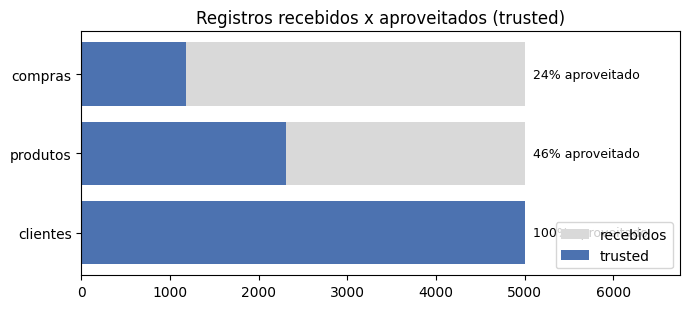

In [7]:
comp_ok, prod_ok = len(tr["compras"]), len(tr["produtos"])
pct_comp, pct_prod = 100 * comp_ok / raw_comp, 100 * prod_ok / raw_prod
quar = rel[rel["acao"] == "quarentena"].sort_values("qtd", ascending=False)
top = quar.iloc[0]
outras = quar[quar["tabela"] == "compras"].iloc[1:]
fora_cascata = int(outras["qtd"].sum())

achado(
    "Só uma parte dos registros chegou limpa",
    f"{pct(pct_prod)} dos produtos e {pct(pct_comp)} das compras passaram para a zona trusted ({num(comp_ok)} de {num(raw_comp)} compras). "
    f"A regra que mais rejeita é '{top['regra']}' em {top['tabela']} ({num(top['qtd'])} ocorrências). "
    f"Quando um produto vai para a quarentena, as compras dele vão junto: por isso as compras são aproveitadas bem menos que os produtos.",
    "Validar produto, preço e estoque na origem, antes de gravar o cadastro. Corrigir o produto devolve ao mesmo tempo as compras ligadas a ele.",
    "Alta (contagem direta dos registros)")

fig, ax = plt.subplots(figsize=(7, 3.2))
tabs = ["clientes", "produtos", "compras"]
ok = [len(tr["clientes"]), prod_ok, comp_ok]
brutos = [raw_cli, raw_prod, raw_comp]
ax.barh(tabs, brutos, color="#D9D9D9", label="recebidos")
ax.barh(tabs, ok, color="#4C72B0", label="trusted")
for i, (a, b) in enumerate(zip(ok, brutos)):
    ax.text(b, i, f"  {100 * a / b:.0f}% aproveitado", va="center", fontsize=9)
ax.set_title("Registros recebidos x aproveitados (trusted)"); ax.legend(loc="lower right"); ax.set_xlim(0, max(brutos) * 1.35)
plt.tight_layout(); plt.show()

### 3.2 Categorias: há diferença real entre elas?

In [8]:
cat = (cubo.groupby("categoria")
       .agg(compras=("id_compra", "size"),
            receita=("valor_liquido", lambda s: s[cubo.loc[s.index, "valida"]].sum()),
            cancel=("valida", lambda s: 100 * (~s).mean()))
       .sort_values("receita", ascending=False))
cat["participacao"] = 100 * cat["receita"] / cat["receita"].sum()
display(cat.round(2))

grupos = [g["valor_liquido"].values for _, g in vend.groupby("categoria")]
p_valor = stats.kruskal(*grupos).pvalue
tabela = pd.crosstab(cubo["categoria"], cubo["valida"])
p_cancel = stats.chi2_contingency(tabela)[1]
topo, base = cat.index[0], cat.index[-1]
dif = 100 * (cat["receita"].iloc[0] / cat["receita"].iloc[-1] - 1)

if p_valor >= ALPHA and p_cancel >= ALPHA:
    reco = "Não priorizar uma categoria só por este resultado: a diferença de receita e de cancelamento entre elas é compatível com acaso. Decidir por margem, estoque e custo de aquisição, que não estão nos dados."
    conf = "Média: o teste não acusa diferença, mas só vale para o volume deste lote"
else:
    reco = (f"Olhar de perto {topo} (maior receita) e as categorias com mais cancelamento: a diferença passou no teste estatístico. "
            "Confirmar com outro lote antes de mudar estoque ou investimento.")
    conf = "Média a alta (teste estatístico significativo)"
achado(
    "Receita e cancelamento por categoria",
    f"{topo} lidera ({brl(cat['receita'].iloc[0])}, {pct(cat['participacao'].iloc[0])} da receita) e {base} fica por último; a distância é de {pct(dif)}. "
    f"Teste de Kruskal-Wallis no valor das compras: {p_texto(p_valor)}. Teste qui-quadrado no cancelamento por categoria: {p_texto(p_cancel)} "
    f"({'sem' if p_valor >= ALPHA and p_cancel >= ALPHA else 'com'} diferença significativa a {ALPHA:.0%}).",
    reco, conf)

,compras,receita,cancel,participacao
categoria,,,,
Esportes,187,324018.25,17.65,16.63
Roupas,197,311430.64,22.84,15.99
Livros,183,304085.78,19.13,15.61
Alimentos,155,266249.86,18.06,13.67
Casa,158,261623.94,23.42,13.43
Eletrônicos,148,244264.64,20.95,12.54
Brinquedos,156,236385.19,23.72,12.13



### Receita e cancelamento por categoria
Esportes lidera (R$ 324.018,25, 16,6% da receita) e Brinquedos fica por último; a distância é de 37,1%. Teste de Kruskal-Wallis no valor das compras: p = 0,979. Teste qui-quadrado no cancelamento por categoria: p = 0,662 (sem diferença significativa a 5%).
-> Recomendação: Não priorizar uma categoria só por este resultado: a diferença de receita e de cancelamento entre elas é compatível com acaso. Decidir por margem, estoque e custo de aquisição, que não estão nos dados.
-> Confiança: Média: o teste não acusa diferença, mas só vale para o volume deste lote


### 3.3 Cancelamentos

In [9]:
canc = cubo[~cubo["valida"]]
taxa = 100 * len(canc) / len(cubo)
perda = canc["valor_liquido"].sum()
bruto_total = cubo["valor_liquido"].sum()
pend = 100 * (cubo["status"] == "pendente").mean()
p_faixa = stats.chi2_contingency(pd.crosstab(cubo["faixa_etaria"], cubo["valida"]))[1]
faixa_c = cubo.groupby("faixa_etaria")["valida"].apply(lambda s: 100 * (~s).mean())

achado(
    "Cancelamento tira uma fatia relevante da receita",
    f"{pct(taxa)} das compras foram canceladas, o que representa {brl(perda)} ({pct(100 * perda / bruto_total)} do valor total vendido). "
    f"Por faixa etária a taxa vai de {pct(faixa_c.min())} ({faixa_c.idxmin()}) a {pct(faixa_c.max())} ({faixa_c.idxmax()}), "
    f"mas essa diferença {'não é' if p_faixa >= ALPHA else 'é'} significativa ({p_texto(p_faixa)}). "
    f"Outros {pct(pend)} das compras estão 'pendente' e entram na receita; se forem canceladas, a receita real cai.",
    "Tratar o cancelamento como problema do processo de compra (pagamento, prazo, estoque), e não de um perfil de cliente ou categoria. Registrar o motivo do cancelamento na origem: hoje os dados só dizem que cancelou.",
    "Alta para o tamanho do cancelamento; baixa para explicar a causa (não há motivo nos dados)")


### Cancelamento tira uma fatia relevante da receita
20,8% das compras foram canceladas, o que representa R$ 558.019,50 (22,3% do valor total vendido). Por faixa etária a taxa vai de 15,8% (55-64) a 25,2% (45-54), mas essa diferença não é significativa (p = 0,324). Outros 19,0% das compras estão 'pendente' e entram na receita; se forem canceladas, a receita real cai.
-> Recomendação: Tratar o cancelamento como problema do processo de compra (pagamento, prazo, estoque), e não de um perfil de cliente ou categoria. Registrar o motivo do cancelamento na origem: hoje os dados só dizem que cancelou.
-> Confiança: Alta para o tamanho do cancelamento; baixa para explicar a causa (não há motivo nos dados)


### 3.4 Tendência e sazonalidade

In [10]:
mensal = vend.groupby("ano_mes")["valor_liquido"].sum()
interior = mensal.iloc[1:-1] if len(mensal) > 3 else mensal      # primeiro e último mês costumam estar incompletos
x = np.arange(len(interior))
reg = stats.linregress(x, interior.values) if len(interior) >= 4 else None
cv = 100 * interior.std() / interior.mean()
melhor, pior = interior.idxmax(), interior.idxmin()
trim = vend.groupby(["ano", "trimestre"])["valor_liquido"].sum()

if reg is not None and reg.pvalue < ALPHA:
    sentido = "crescimento" if reg.slope > 0 else "queda"
    tend = f"Há {sentido} significativo ao longo dos meses ({p_texto(reg.pvalue)})."
    reco = "Investigar o que mudou ao longo do período antes de projetar o próximo trimestre."
else:
    tend = (f"Não há tendência significativa de crescimento ou queda ({p_texto(reg.pvalue)})." if reg is not None
            else "Há poucos meses para estimar tendência.")
    reco = "Planejar com a média mensal e a faixa de variação, sem assumir crescimento. Rodar mais lotes para separar sazonalidade de ruído."
achado(
    "Receita mensal sem tendência clara" if (reg is None or reg.pvalue >= ALPHA) else f"Receita mensal em {sentido}",
    f"Considerando os meses completos ({len(interior)}), a receita média é {brl(interior.mean())} por mês, com variação de {pct(cv)} (desvio padrão sobre a média). "
    f"Melhor mês: {melhor} ({brl(interior.max())}); pior: {pior} ({brl(interior.min())}). {tend} "
    f"O primeiro e o último mês ({mensal.index[0]} e {mensal.index[-1]}) ficam de fora por estarem incompletos.",
    reco, "Média a baixa: poucos meses e dados simulados")


### Receita mensal sem tendência clara
Considerando os meses completos (11), a receita média é R$ 159.806,12 por mês, com variação de 15,2% (desvio padrão sobre a média). Melhor mês: 2026-07 (R$ 209.200,72); pior: 2026-02 (R$ 115.549,23). Não há tendência significativa de crescimento ou queda (p = 0,376). O primeiro e o último mês (2025-10 e 2026-10) ficam de fora por estarem incompletos.
-> Recomendação: Planejar com a média mensal e a faixa de variação, sem assumir crescimento. Rodar mais lotes para separar sazonalidade de ruído.
-> Confiança: Média a baixa: poucos meses e dados simulados


### 3.5 Clientes: quem compra

In [11]:
cli_stat = (dim_c.merge(vend.groupby("id_cliente").agg(receita=("valor_liquido", "sum"), compras=("id_compra", "size")),
                        left_on="id_cliente", right_index=True, how="left").fillna({"receita": 0, "compras": 0}))
ativos = 100 * (cli_stat["compras"] > 0).mean()
uma = 100 * (rfm["frequencia"] == 1).mean()
por_faixa = cli_stat.groupby("faixa_etaria").agg(clientes=("id_cliente", "size"), receita=("receita", "sum"))
por_faixa["pct_clientes"] = 100 * por_faixa["clientes"] / por_faixa["clientes"].sum()
por_faixa["pct_receita"] = 100 * por_faixa["receita"] / por_faixa["receita"].sum()
por_faixa["receita_por_cliente"] = por_faixa["receita"] / por_faixa["clientes"]
display(por_faixa.round(2))
melhor_f = por_faixa["receita_por_cliente"].idxmax()

achado(
    "Poucos clientes cadastrados compraram, e quase ninguém repete",
    f"Só {pct(ativos)} dos clientes cadastrados têm alguma compra não cancelada. Entre os que compraram, {pct(uma)} compraram uma única vez. "
    f"A faixa {melhor_f} gera a maior receita por cliente cadastrado ({brl(por_faixa.loc[melhor_f, 'receita_por_cliente'])}) "
    f"e responde por {pct(por_faixa.loc[melhor_f, 'pct_receita'])} da receita com {pct(por_faixa.loc[melhor_f, 'pct_clientes'])} dos clientes.",
    "Dois alvos: (1) ativar a base que nunca comprou, com uma primeira oferta; (2) levar quem comprou uma vez para a segunda compra, com cupom ou recomendação no prazo certo.",
    "Alta para os percentuais; média para a diferença entre faixas (não testada)")

,clientes,receita,pct_clientes,pct_receita,receita_por_cliente
faixa_etaria,,,,,
18-24,548,202655.41,10.96,10.40,369.81
25-34,777,307931.09,15.54,15.81,396.31
35-44,747,249311.49,14.94,12.80,333.75
45-54,821,338949.31,16.42,17.40,412.85
55-64,808,361899.74,16.16,18.58,447.90
65+,1299,487311.26,25.98,25.02,375.14



### Poucos clientes cadastrados compraram, e quase ninguém repete
Só 17,4% dos clientes cadastrados têm alguma compra não cancelada. Entre os que compraram, 92,2% compraram uma única vez. A faixa 55-64 gera a maior receita por cliente cadastrado (R$ 447,90) e responde por 18,6% da receita com 16,2% dos clientes.
-> Recomendação: Dois alvos: (1) ativar a base que nunca comprou, com uma primeira oferta; (2) levar quem comprou uma vez para a segunda compra, com cupom ou recomendação no prazo certo.
-> Confiança: Alta para os percentuais; média para a diferença entre faixas (não testada)


### 3.6 Segmentos de clientes (RFM + K-Means)

In [12]:
perfil = perfil.copy()
col_pc = [c for c in perfil.columns if "clientes" in c and c != "clientes"][0]
col_pv = [c for c in perfil.columns if "valor" in c and c.startswith(("%", "pct"))][0]
ordem = {"VIP": 0, "Regular": 1}
perfil["_o"] = perfil["segmento"].map(lambda s: ordem.get(s, 2))
perfil = perfil.sort_values("_o").drop(columns="_o")
display(perfil.round(2))
vip = perfil.iloc[0]
k_usado = len(perfil)
sil_k = aval.loc[aval.iloc[:, 0] == k_usado, "silhouette"].iloc[0]
sil_max = aval["silhouette"].max()
k_max = int(aval.loc[aval["silhouette"].idxmax(), aval.columns[0]])

forca = "fraca" if sil_k < 0.25 else ("moderada" if sil_k < 0.5 else "boa")
d2 = lambda x: f"{x:.2f}".replace(".", ",")
achado(
    f"Segmentos de clientes: perfil do VIP e separação {forca} entre grupos",
    f"O K-Means separou {k_usado} grupos. O VIP tem {pct(vip[col_pc])} dos clientes e {pct(vip[col_pv])} do valor, "
    f"com {d2(vip['frequencia_media'])} compras em média contra {d2(perfil['frequencia_media'].min())} no grupo de menor frequência. "
    f"A silhouette do modelo é {d2(sil_k)} ({forca}; o máximo testado, {d2(sil_max)}, foi com K = {k_max}). Abaixo de 0,5, os grupos se tocam nas bordas. "
    f"Como {pct(uma)} dos clientes têm uma só compra, a frequência quase não separa os grupos: quem separa é recência e valor.",
    "Usar o VIP para fidelidade e acesso antecipado, e o grupo de menor engajamento para reativação com custo limitado. Tratar os rótulos como ponto de partida e conferir o perfil antes de uma campanha.",
    f"Média: a separação entre grupos é {forca} e a frequência tem pouca variação")

if spark_perfil is not None:
    print("\nComparação com o consolidado do Spark (todos os lotes):")
    display(spark_perfil)

,segmento,clientes,recencia_media,frequencia_media,valor_medio,valor_total,% clientes,% do valor,faixa_etaria_comum,categoria_top
0,VIP,68,125.82,2.03,4444.50,302226.04,7.83,15.51,65+,Casa
1,Regular,422,96.33,1.00,1957.49,826062.14,48.62,42.40,65+,Esportes
2,Em risco,378,278.07,1.00,2168.70,819770.12,43.55,42.08,65+,Livros



### Segmentos de clientes: perfil do VIP e separação moderada entre grupos
O K-Means separou 3 grupos. O VIP tem 7,8% dos clientes e 15,5% do valor, com 2,03 compras em média contra 1,00 no grupo de menor frequência. A silhouette do modelo é 0,41 (moderada; o máximo testado, 0,60, foi com K = 2). Abaixo de 0,5, os grupos se tocam nas bordas. Como 92,2% dos clientes têm uma só compra, a frequência quase não separa os grupos: quem separa é recência e valor.
-> Recomendação: Usar o VIP para fidelidade e acesso antecipado, e o grupo de menor engajamento para reativação com custo limitado. Tratar os rótulos como ponto de partida e conferir o perfil antes de uma campanha.
-> Confiança: Média: a separação entre grupos é moderada e a frequência tem pouca variação

Comparação com o consolidado do Spark (todos os lotes):


,segmento,clientes,recencia_media,frequencia_media,valor_medio,valor_total,pct_clientes,pct_valor
0,VIP,68,124.8,2.03,4444.50,302226.04,7.8,15.5
1,Regular,570,206.1,1.00,2530.62,1442451.97,65.7,74.0
2,Baixo engajamento,230,119.5,1.00,884.26,203380.29,26.5,10.4


## 4. Painel de resumo

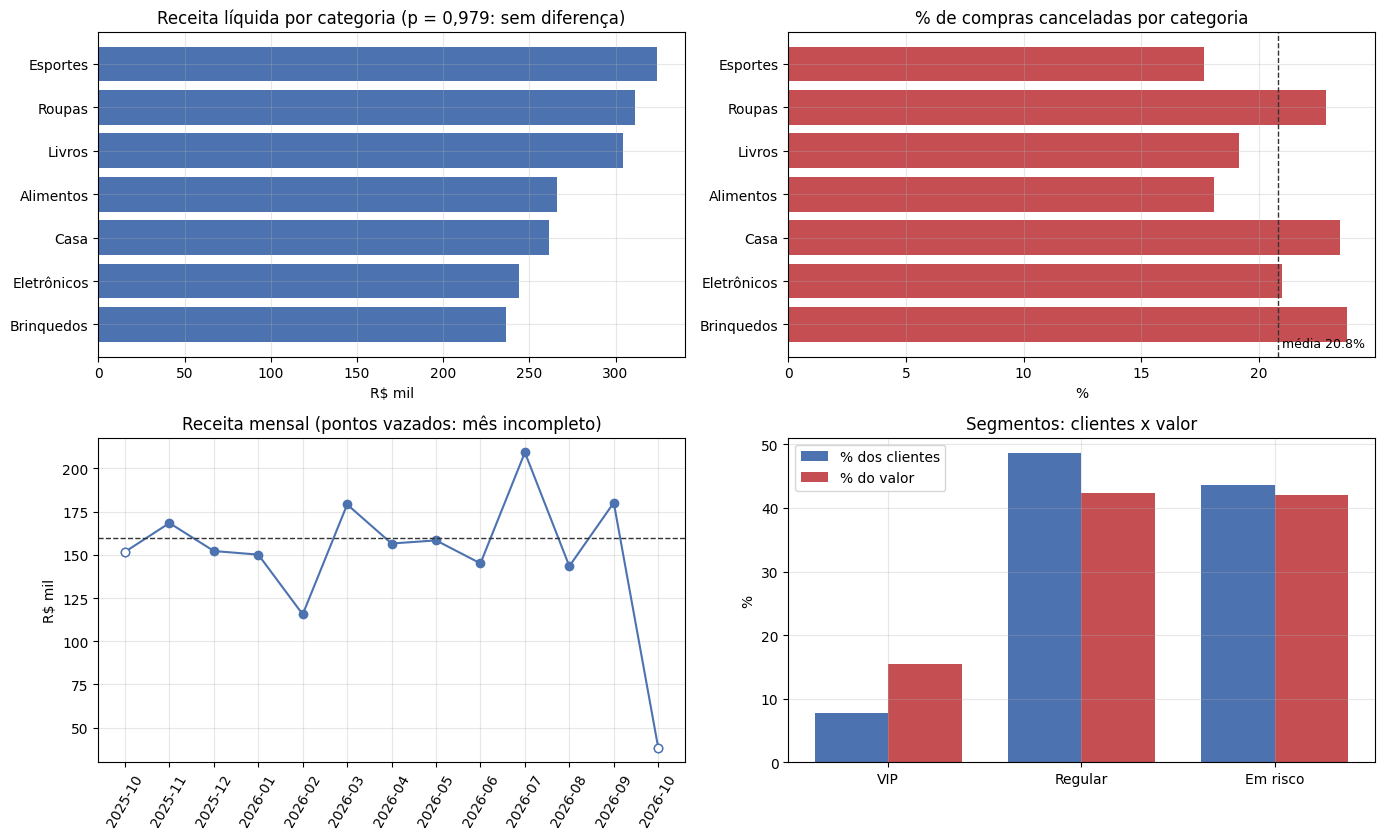

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8.5))
azul, vermelho = "#4C72B0", "#C44E52"

c = cat.sort_values("receita")
ax[0, 0].barh(c.index, c["receita"] / 1e3, color=azul)
ax[0, 0].set_title(f"Receita líquida por categoria ({p_texto(p_valor)}: " + ("sem" if p_valor >= ALPHA else "com") + " diferença)")
ax[0, 0].set_xlabel("R$ mil")

ax[0, 1].barh(c.index, c["cancel"], color=vermelho)
ax[0, 1].axvline(taxa, color="#333333", ls="--", lw=1)
ax[0, 1].text(taxa, -0.6, f" média {taxa:.1f}%", fontsize=9, va="bottom")
ax[0, 1].set_title("% de compras canceladas por categoria"); ax[0, 1].set_xlabel("%")

ax[1, 0].plot(mensal.index, mensal.values / 1e3, marker="o", color=azul)
ax[1, 0].plot([mensal.index[0], mensal.index[-1]], [mensal.iloc[0] / 1e3, mensal.iloc[-1] / 1e3], ls="none", marker="o", mfc="white", color=azul)
ax[1, 0].axhline(interior.mean() / 1e3, color="#333333", ls="--", lw=1)
ax[1, 0].set_title("Receita mensal (pontos vazados: mês incompleto)"); ax[1, 0].set_ylabel("R$ mil")
ax[1, 0].tick_params(axis="x", rotation=60)

x = np.arange(len(perfil)); w = 0.38
ax[1, 1].bar(x - w / 2, perfil[col_pc], w, label="% dos clientes", color=azul)
ax[1, 1].bar(x + w / 2, perfil[col_pv], w, label="% do valor", color=vermelho)
ax[1, 1].set_xticks(x); ax[1, 1].set_xticklabels(perfil["segmento"])
ax[1, 1].set_title("Segmentos: clientes x valor"); ax[1, 1].set_ylabel("%"); ax[1, 1].legend()
for a in ax.ravel():
    a.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 5. Limitações, próximos passos e relatório

In [14]:
quar_comp = 100 - pct_comp
limitacoes = [
    "Os dados vêm de um simulador. Distribuições quase uniformes (categorias com receita parecida, cancelamento parecido em todos os grupos) são esperadas e não indicam comportamento de clientes reais.",
    f"A limpeza descartou {pct(quar_comp)} das compras recebidas. Os resultados descrevem só as compras que passaram nas regras; se as rejeitadas tiverem perfil diferente, há viés.",
    "Cada ciclo do simulador reinicia os ids. Por isso os lotes foram tratados como bases separadas (chave lote + id) e não se pode acompanhar o mesmo cliente entre lotes.",
    f"A receita inclui compras 'pendente' ({pct(pend)} do total). Só 'cancelado' foi excluído.",
    f"Receita não é lucro: não há custo, margem nem frete nos dados. {pct(uma)} dos clientes com compra têm uma só, então o RFM tem pouca informação de frequência.",
    "Os testes estatísticos foram feitos sem correção para comparações múltiplas e sobre poucos meses; devem ser lidos como indício, não como prova.",
    f"A silhouette ({d2(sil_k)}) indica separação {forca} entre os grupos. A segmentação ajuda a priorizar ações, mas não define fronteiras rígidas.",
]
proximos = [
    "Rodar mais lotes (e o consolidado no Spark) e conferir se os achados se repetem.",
    "Registrar o motivo do cancelamento e a margem por produto na origem, para recomendações financeiras.",
    "Validar produto e preço na origem para aproveitar mais compras na zona trusted.",
    "Testar uma ação de segunda compra e medir o efeito (grupo de teste e grupo de controle).",
    "Comparar o K-Means com outros algoritmos e outros conjuntos de variáveis (categoria preferida, desconto médio).",
]
print("Limitações:")
for i in limitacoes:
    print(" -", i)
print("\nPróximos passos:")
for i in proximos:
    print(" -", i)

Limitações:
 - Os dados vêm de um simulador. Distribuições quase uniformes (categorias com receita parecida, cancelamento parecido em todos os grupos) são esperadas e não indicam comportamento de clientes reais.
 - A limpeza descartou 76,3% das compras recebidas. Os resultados descrevem só as compras que passaram nas regras; se as rejeitadas tiverem perfil diferente, há viés.
 - Cada ciclo do simulador reinicia os ids. Por isso os lotes foram tratados como bases separadas (chave lote + id) e não se pode acompanhar o mesmo cliente entre lotes.
 - A receita inclui compras 'pendente' (19,0% do total). Só 'cancelado' foi excluído.
 - Receita não é lucro: não há custo, margem nem frete nos dados. 92,2% dos clientes com compra têm uma só, então o RFM tem pouca informação de frequência.
 - Os testes estatísticos foram feitos sem correção para comparações múltiplas e sobre poucos meses; devem ser lidos como indício, não como prova.
 - A silhouette (0,41) indica separação moderada entre os grup

In [15]:
from datetime import date

linhas = [f"# Insights finais | Projeto Gardenia (lote {LOTE})", "",
          f"Gerado em {date.today():%d/%m/%Y}. Dados de um simulador; veja as limitações.", "",
          "## Números principais", "", "| Indicador | Valor |", "|---|---|"]
linhas += [f"| {r.indicador} | {r.valor} |" for r in kpi.itertuples()]
linhas += ["", "## Achados"]
for n, i in enumerate(insights, 1):
    linhas += ["", f"### {n}. {i['titulo']}", "", i["dados"], "", f"**Recomendação:** {i['recomendacao']}", "",
               f"**Confiança:** {i['confianca']}"]
linhas += ["", "## Limitações"] + [f"- {x}" for x in limitacoes]
linhas += ["", "## Próximos passos"] + [f"- {x}" for x in proximos]
relatorio = "\n".join(linhas) + "\n"

SAIDA = f"{DRIVE_PASTA}/insights" if (SALVAR_NO_DRIVE and FONTE == "drive") else "insights"
os.makedirs(SAIDA, exist_ok=True)
with open(os.path.join(SAIDA, f"insights_{LOTE}.md"), "w", encoding="utf-8") as f:
    f.write(relatorio)
fig.savefig(os.path.join(SAIDA, f"insights_{LOTE}.png"), dpi=110, bbox_inches="tight")
print(f"Relatório salvo em {SAIDA}/insights_{LOTE}.md e {SAIDA}/insights_{LOTE}.png")

Relatório salvo em /content/drive/MyDrive/gardenia/insights/insights_1.md e /content/drive/MyDrive/gardenia/insights/insights_1.png


## 6. Checklist antes do commit

- [ ] os notebooks 03, 04 e 06 foram rodados com o mesmo `LOTE`;
- [ ] cada achado tem número, recomendação e confiança;
- [ ] as limitações foram lidas e fazem sentido para o seu conjunto de dados;
- [ ] se rodar com outro lote, releia os textos: eles são gerados a partir dos números, mas a interpretação final é sua.